# NB-11 — Atenção, Transformers e VLMs (Cap. 2, §2.9 e §2.10)

> **Demonstração didática.** Base Washington (GW20, CIIR/UMass, uso não comercial, não redistribuir): 20 páginas, treino em CPU, vocabulário fechado. Os números **não** são comparáveis com a literatura nem com o BRESSAY; servem para mostrar o mecanismo de cada família do Cap. 2. Dados em `notebooks/dados/washington/` (fora do git; ver `lib/gw_demo.py`).

(1) **Atenção** em poucas linhas, com pesos visualizáveis; (2) um **Transformer encoder** no lugar da BiLSTM do NB-10 (mesma CNN e mesma perda CTC); (3) VLMs: remete ao NB-02, que roda os modelos reais pela OpenRouter.

In [1]:
# Parâmetros
from pathlib import Path
SAIDA = Path('saidas/NB-11')
SEED = 0
EPOCAS = 30


In [2]:
import sys
sys.path.insert(0, '.')
import numpy as np, matplotlib.pyplot as plt
from lib import gw_demo as gw, gw_modelos as m
SAIDA.mkdir(parents=True, exist_ok=True)
np.random.seed(SEED)
tr, va, te = m.carregar(gw.TREINO), m.carregar(gw.VALID), m.carregar(gw.TESTE)
print(f'palavras: treino {len(tr[0])} (páginas 0-13) | validação {len(va[0])} | teste {len(te[0])} (páginas 17-19)')

palavras: treino 3439 (páginas 0-13) | validação 684 | teste 707 (páginas 17-19)


## 1. Atenção por produto escalar (mecanismo)
`atenção(Q,K,V) = softmax(QKᵀ/√d)·V`: cada posição decide quanto olhar para as demais. Exemplo sobre as colunas de uma palavra.

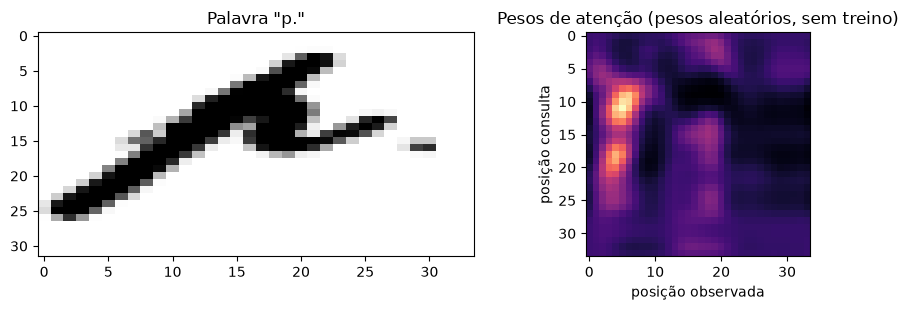

In [3]:
import torch
x = torch.from_numpy(m.feixe_colunas(te[0][0])).float()            # (T, 9) colunas como tokens
T, d = x.shape
torch.manual_seed(SEED)
Wq, Wk = torch.randn(d, 16), torch.randn(d, 16)
A = torch.softmax((x @ Wq) @ (x @ Wk).T / 16**.5, dim=-1)   # pesos de atenção (T, T)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={'width_ratios': [1.2, 1]})
ax[0].imshow(te[0][0], cmap='gray_r', aspect='auto'); ax[0].set_title(f'Palavra "{te[1][0]}"')
ax[1].imshow(A, cmap='magma'); ax[1].set_title('Pesos de atenção (pesos aleatórios, sem treino)'); ax[1].set_xlabel('posição observada'); ax[1].set_ylabel('posição consulta')
plt.tight_layout(); plt.savefig(SAIDA/'atencao.png', dpi=130); plt.show()

## 2. CNN + Transformer encoder + CTC
Sem recorrência: toda posição vê todas as outras em um passo. A ordem vem de embeddings posicionais. O treino na CPU leva ~25 min; checkpoint em `dados/washington/modelos/`.

463,527 parâmetros | épocas: 30 | CER teste (micro): 0.282


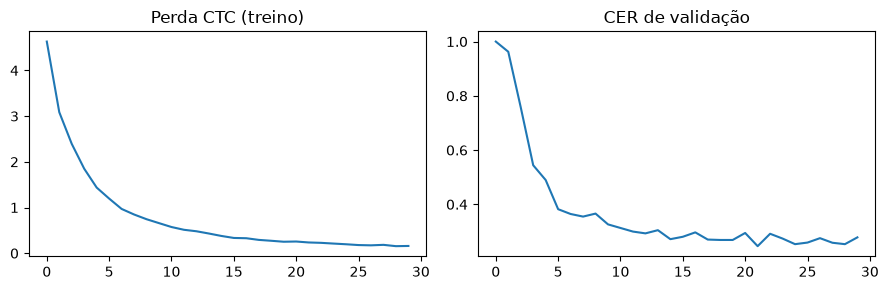

In [4]:
modelo = m.crnn('transformer')
hist = m.treinar_ou_carregar('transformer_ctc', modelo, tr[0], tr[1], EPOCAS, lr=1e-3, imgs_va=va[0][:300], rot_va=va[1][:300])
pred = m.prever_texto(modelo, te[0])
print(f'{m.n_parametros(modelo):,} parâmetros | épocas: {len(hist)} | CER teste (micro): {m.micro_cer(te[1], pred):.3f}')
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].plot([h['perda'] for h in hist]); ax[0].set_title('Perda CTC (treino)')
if 'cer_val' in hist[0]: ax[1].plot([h['cer_val'] for h in hist]); ax[1].set_title('CER de validação')
plt.tight_layout(); plt.savefig(SAIDA/'curvas.png', dpi=130); plt.show()

In [5]:
import json
cr = m.PASTA_MODELOS / 'crnn_ctc.json'
if cr.exists():
    h0 = json.loads(cr.read_text())
    print(f'CRNN (NB-10): CER val final {h0[-1].get("cer_val", float("nan")):.3f} em {len(h0)} épocas | Transformer: {hist[-1].get("cer_val", float("nan")):.3f} em {len(hist)} épocas')

CRNN (NB-10): CER val final 0.226 em 20 épocas | Transformer: 0.278 em 30 épocas


## 3. VLMs e LLMs multimodais
Não cabem treino local: são modelos de bilhões de parâmetros pré-treinados. A comparação com a plataforma está no **NB-02** (8 modelos da OpenRouter na página 1680-069, cosseno 0,983–0,994, CER 0,8–3,1 %). A diferença entre este notebook e aquelas linhas mostra o efeito de escala de dados e de pré-treino.

**Leitura:** com poucos dados, Transformers sem pré-treino costumam convergir mais devagar que modelos recorrentes e podem ficar atrás do CRNN. Sua vantagem aparece com muitos dados e pré-treino (TrOCR, VLMs).